# Fatores associados à gravidade dos acidentes em rodovias federais brasileiras (2021–2025)

**Disciplina:** Python para Ciência de Dados  
**Atividade:** Atividade Prática Supervisionada (APS)  
**Professor:** Paulo C. Marques F.  
**Integrantes:** Camille Souza, Elora Rocha, Gabriela Afif e Maria Luiza Sevilha

## 1. Introdução e pergunta de pesquisa

Os acidentes em rodovias federais geram mortes, lesões e custos sociais. Contudo, contar ocorrências não é suficiente: acidentes semelhantes em quantidade podem ter consequências muito diferentes. Este trabalho investiga a **gravidade** dos acidentes registrados pela Polícia Rodoviária Federal (PRF) entre 2021 e 2025.

> **Quais características temporais, espaciais, viárias e ambientais estão associadas à presença de mortos ou feridos graves nos acidentes registrados pela PRF?**

Uma ocorrência é classificada como grave quando `mortos + feridos_graves > 0`. O objetivo é descrever os padrões mais relevantes, estimar associações por regressão logística e verificar como os modelos se comportam em dados posteriores aos usados na estimação.

## 2. Dados e estratégia

Foram usados os arquivos de acidentes **agrupados por ocorrência** do [Portal de Dados Abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf). Cada linha representa um acidente. Os cinco arquivos anuais cobrem de 1º de janeiro de 2021 a 31 de dezembro de 2025 e seguem o [dicionário oficial](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes).

A análise separa 2021–2024 para estimação (270.141 ocorrências; 28,28% graves) e 2025 para avaliação (72.529 ocorrências; 28,25% graves). O **Modelo A** usa horário, UF, clima, pista e trecho urbano ou rural. O **Modelo B** acrescenta tipo, causa e número de veículos. Como tipo e causa são registrados depois do acidente, o Modelo B é uma descrição ampliada da ocorrência, não uma previsão anterior ao acidente.

Os resultados representam acidentes registrados pela PRF em rodovias federais. A base não informa fluxo de veículos ou quilômetros percorridos; portanto, não mede o risco de trafegar em uma UF ou rodovia. Todas as relações são interpretadas como associações, não como efeitos causais.

## 3. Preparação e qualidade dos dados

Os CSVs são lidos individualmente com caminhos relativos. Os arquivos brutos permanecem inalterados em `dados/brutos/`.

In [1]:
import pandas as pd
import numpy as np
from plotnine import *
from mizani.formatters import percent_format

theme_set(
    theme_minimal(base_size=12)
    + theme(
        figure_size=(10, 6),
        plot_title=element_text(size=16, weight="bold", ha="left"),
        plot_subtitle=element_text(size=11, ha="left")
    )
)

dados_2021 = pd.read_csv("dados/brutos/datatran2021.csv", sep=";", encoding="latin1", decimal=",")
dados_2022 = pd.read_csv("dados/brutos/datatran2022.csv", sep=";", encoding="latin1", decimal=",")
dados_2023 = pd.read_csv("dados/brutos/datatran2023.csv", sep=";", encoding="latin1", decimal=",")
dados_2024 = pd.read_csv("dados/brutos/datatran2024.csv", sep=";", encoding="latin1", decimal=",")
dados_2025 = pd.read_csv("dados/brutos/datatran2025.csv", sep=";", encoding="latin1", decimal=",")

In [2]:
dados_2021["ano_arquivo"] = 2021
dados_2022["ano_arquivo"] = 2022
dados_2023["ano_arquivo"] = 2023
dados_2024["ano_arquivo"] = 2024
dados_2025["ano_arquivo"] = 2025

dados = pd.concat(
    [dados_2021, dados_2022, dados_2023, dados_2024, dados_2025],
    ignore_index=True
)

dados["id"] = dados["id"].astype("Int64")
dados["data_inversa"] = pd.to_datetime(dados["data_inversa"], errors="coerce")

assert len(dados) == 342670
assert dados["id"].is_unique
assert dados["data_inversa"].notna().all()

### 3.1 Diagnóstico principal

A tabela reúne apenas as verificações que afetam diretamente a análise.

In [3]:
base = dados.copy()

base["soma_estados_fisicos"] = (
    base["mortos"]
    + base["feridos_leves"]
    + base["feridos_graves"]
    + base["ilesos"]
    + base["ignorados"]
)
base["diferenca_pessoas"] = base["pessoas"] - base["soma_estados_fisicos"]
base["divergencia_pessoas"] = base["diferenca_pessoas"] != 0

divergencias_ano = base.groupby("ano_arquivo", as_index=False).agg(
    divergencias=("divergencia_pessoas", "sum"),
    percentual=("divergencia_pessoas", "mean")
)
diferencas_frequentes = base.loc[
    base["divergencia_pessoas"], "diferenca_pessoas"
].value_counts()

grupo_complexo = (
    (base["veiculos"] >= 3)
    & (base["ignorados"] > 0)
)
percentual_divergente_grupo = (
    base.loc[grupo_complexo, "divergencia_pessoas"].mean()
)

assert (base.loc[base["divergencia_pessoas"], "veiculos"] >= 3).all()
assert (base.loc[base["divergencia_pessoas"], "ignorados"] > 0).all()
assert grupo_complexo.sum() == 49950

assert (
    dados["feridos"]
    == dados["feridos_leves"] + dados["feridos_graves"]
).all()
assert (base.loc[base["divergencia_pessoas"], "diferenca_pessoas"] < 0).all()

tabela_qualidade = pd.DataFrame({
    "verificação": [
        "Ocorrências",
        "IDs únicos",
        "Linhas duplicadas",
        "Datas inválidas",
        "Classificações ausentes",
        "Divergências em pessoas"
    ],
    "resultado": [
        len(dados),
        dados["id"].nunique(),
        dados.duplicated().sum(),
        dados["data_inversa"].isna().sum(),
        dados["classificacao_acidente"].isna().sum(),
        base["divergencia_pessoas"].sum()
    ]
})

tabela_qualidade

,verificação,resultado
0,Ocorrências,342670
1,IDs únicos,342670
2,Linhas duplicadas,0
3,Datas inválidas,0
4,Classificações ausentes,5
5,Divergências em pessoas,18541


Existem **18.541 divergências (5,41%)** entre `pessoas` e a soma dos estados físicos. Em todos esses casos, a soma é maior; as diferenças mais frequentes são −1 (11.844 ocorrências) e −2 (4.808). O percentual anual varia apenas de 5,27% a 5,56%, sem concentração em um arquivo específico. Todas as divergências aparecem no grupo com pelo menos três veículos e alguma pessoa em estado ignorado: são 18.541 de 49.950 ocorrências desse grupo (37,1%). Como não há justificativa documental para corrigir os registros, os valores são preservados e `pessoas` não entra nos modelos.

Também foram verificadas as categorias de UF, clima, pista, uso do solo, tipo e causa. Não há espaços excedentes nem categorias de 2025 ausentes em 2021–2024. Grafias evidentemente equivalentes de duas causas são unificadas, reduzindo a variável de 76 para 73 categorias. As causas raras são agrupadas somente depois da divisão temporal.

In [4]:
causas_equivalentes = {
    "Transitar no Acostamento": "Transitar no acostamento",
    "Ingestão de álcool e/ou substâncias psicoativas pelo pedestre":
        "Pedestre: ingestão de álcool ou substâncias psicoativas",
    "Ingestão de álcool ou de substâncias psicoativas pelo pedestre":
        "Pedestre: ingestão de álcool ou substâncias psicoativas",
    "Pedestre - Ingestão de álcool/ substâncias psicoativas":
        "Pedestre: ingestão de álcool ou substâncias psicoativas"
}

base["causa_acidente"] = base["causa_acidente"].replace(causas_equivalentes)

assert base["causa_acidente"].nunique() == 73

variaveis_auditadas = [
    "uf", "condicao_metereologica", "tipo_pista",
    "uso_solo", "tipo_acidente", "causa_acidente"
]

for variavel in variaveis_auditadas:
    categorias_treino = set(base.loc[base["ano_arquivo"] <= 2024, variavel])
    categorias_teste = set(base.loc[base["ano_arquivo"] == 2025, variavel])
    valores = base[variavel].astype(str)
    assert categorias_teste.issubset(categorias_treino)
    assert (valores == valores.str.strip()).all()

base["ano"] = base["data_inversa"].dt.year
base["hora"] = base["horario"].str[:2].astype(int)
base["grave"] = (
    (base["mortos"] + base["feridos_graves"]) > 0
).astype(int)
base["trecho"] = base["uso_solo"].map({"Sim": "Urbano", "Não": "Rural"})
base["faixa_horaria"] = pd.cut(
    base["hora"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Madrugada", "Manhã", "Tarde", "Noite"]
)

treino = base[base["ano"] <= 2024].copy()
teste = base[base["ano"] == 2025].copy()

assert len(treino) == 270141
assert len(teste) == 72529
assert treino[["grave", "faixa_horaria", "uf", "condicao_metereologica", "tipo_pista", "trecho"]].notna().all().all()
assert teste[["grave", "faixa_horaria", "uf", "condicao_metereologica", "tipo_pista", "trecho"]].notna().all().all()

## 4. Análise exploratória

Das 342.670 ocorrências, 96.876 (28,3%) são graves. A análise exploratória responde a três perguntas diretamente ligadas ao estudo: estabilidade temporal, diferenças entre tipos comuns de acidente e associação conjunta entre pista e trecho.

### 4.1 A gravidade mudou no período?

In [5]:
por_ano = base.groupby("ano", as_index=False).agg(
    ocorrencias=("id", "size"),
    graves=("grave", "sum"),
    prop_grave=("grave", "mean"),
    mortos=("mortos", "sum")
)

tabela_anual = por_ano.copy()
tabela_anual.columns = ["Ano", "Ocorrências", "Graves", "Proporção grave", "Mortos"]
tabela_anual["Proporção grave"] = tabela_anual["Proporção grave"].map("{:.1%}".format).str.replace(".", ",")

tabela_anual

,Ano,Ocorrências,Graves,Proporção grave,Mortos
0,2021,64567,18118,"28,1%",5397
1,2022,64606,18409,"28,5%",5441
2,2023,67766,19212,"28,4%",5627
3,2024,73202,20644,"28,2%",6163
4,2025,72529,20493,"28,3%",6043


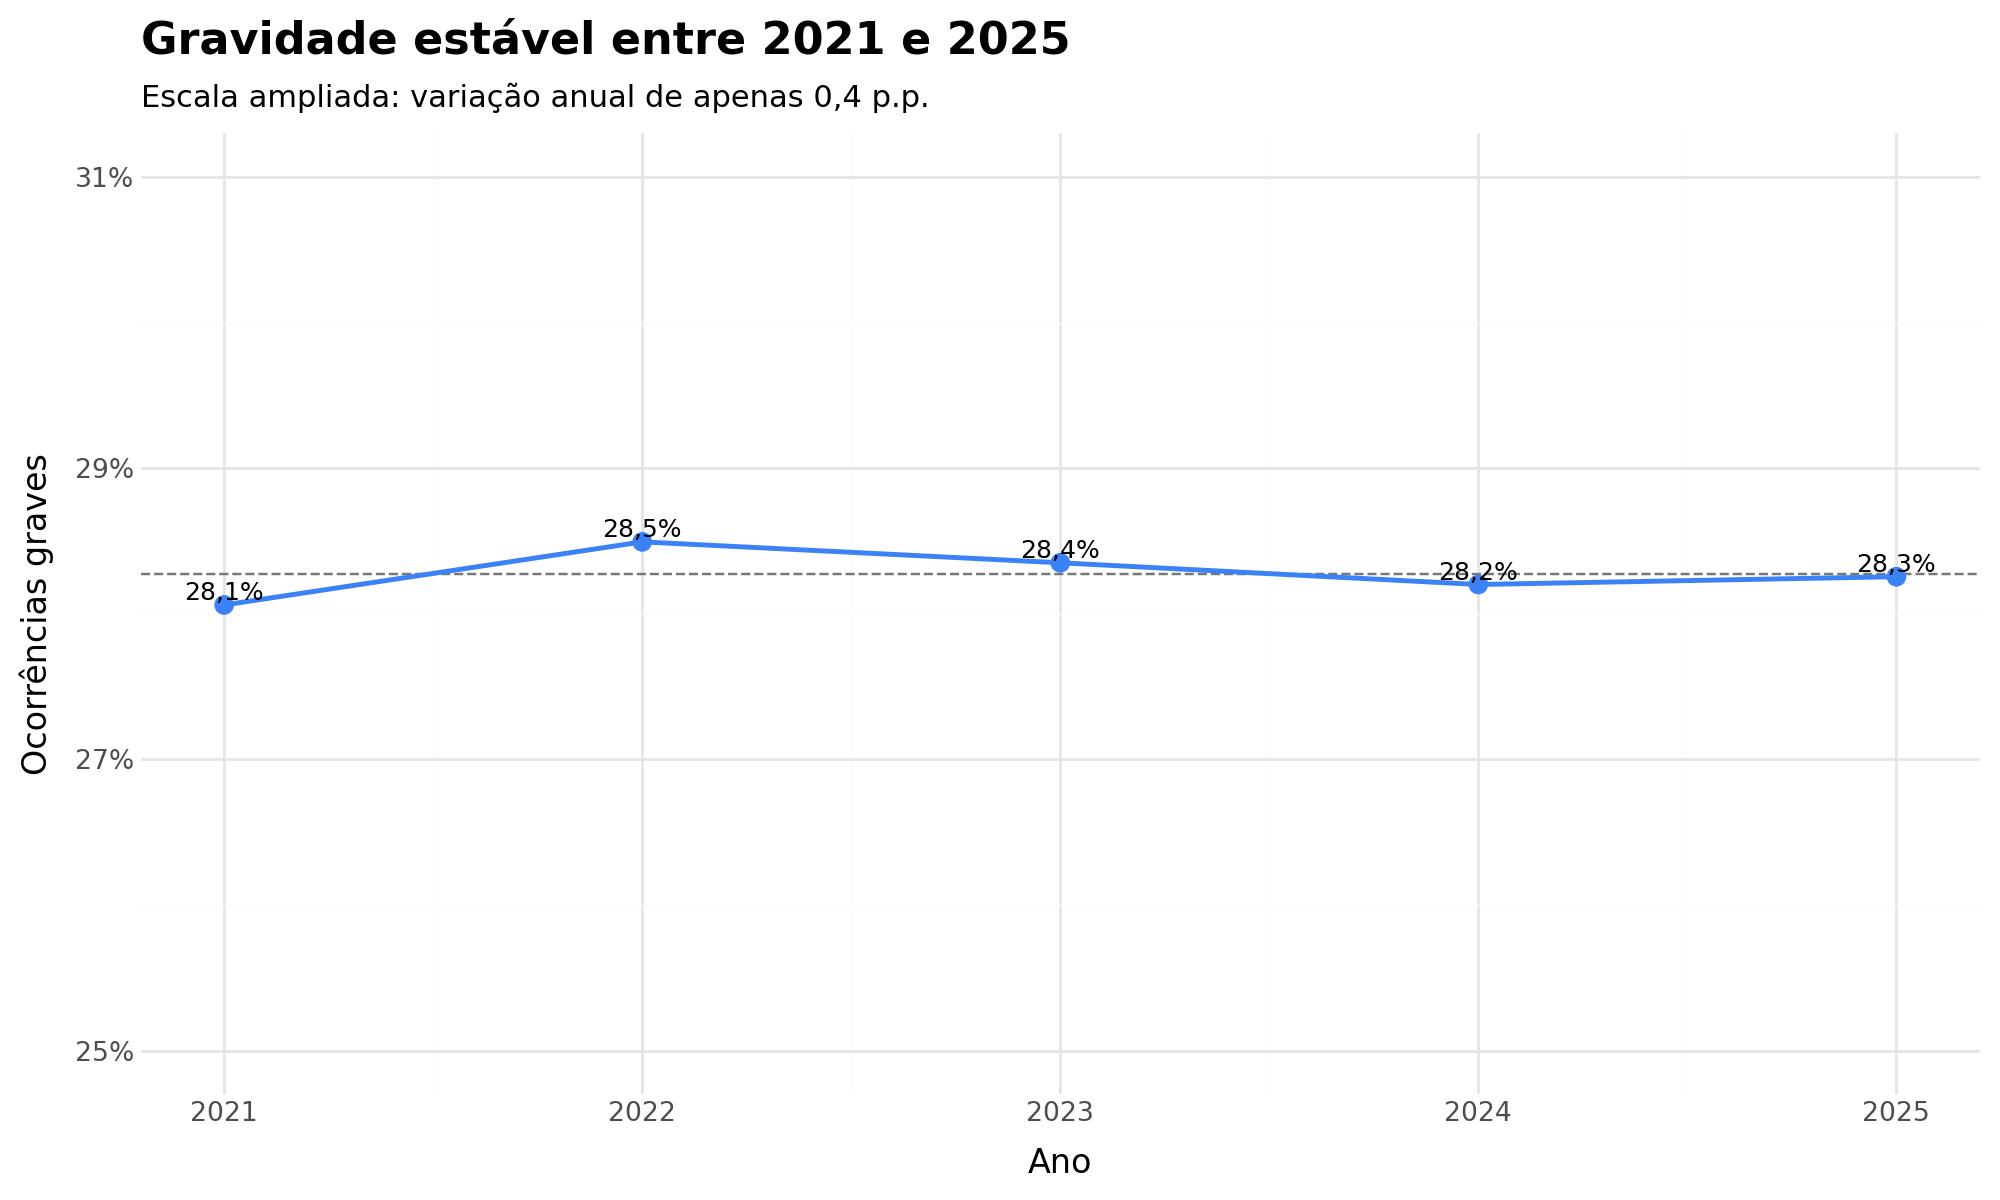

In [6]:
por_ano["rótulo"] = por_ano["prop_grave"].map("{:.1%}".format).str.replace(".", ",")
media_grave = base["grave"].mean()

grafico_anual = (
    ggplot(por_ano, aes(x="ano", y="prop_grave", group=1))
    + geom_hline(yintercept=media_grave, linetype="dashed", color="#777777")
    + geom_line(color="#3B82F6", size=1)
    + geom_point(color="#3B82F6", size=3)
    + geom_text(aes(label="rótulo"), nudge_y=0.0008, size=9)
    + scale_x_continuous(breaks=range(2021, 2026))
    + scale_y_continuous(
        labels=percent_format(),
        limits=(0.25, 0.31),
        breaks=[0.25, 0.27, 0.29, 0.31]
    )
    + labs(
        x="Ano",
        y="Ocorrências graves",
        title="Gravidade estável entre 2021 e 2025",
        subtitle="Escala ampliada: variação anual de apenas 0,4 p.p."
    )
)

grafico_anual

As ocorrências aumentaram de 64.567 em 2021 para 72.529 em 2025, e os mortos passaram de 5.397 para 6.043. Entretanto, a proporção grave permaneceu entre 28,1% e 28,5%. Sem dados de fluxo, o aumento das contagens não representa aumento do risco de trafegar.

### 4.2 Quais tipos comuns apresentam maior gravidade?

O gráfico inclui somente tipos com pelo menos 10.000 registros, evitando comparações dominadas por categorias pequenas.

In [7]:
por_tipo = base.groupby("tipo_acidente", as_index=False).agg(
    ocorrencias=("id", "size"),
    prop_grave=("grave", "mean")
)
por_tipo = por_tipo[por_tipo["ocorrencias"] >= 10000].copy()
por_tipo["n"] = por_tipo["ocorrencias"].map("{:,.0f}".format).str.replace(",", ".")
por_tipo["percentual"] = por_tipo["prop_grave"].map("{:.1%}".format).str.replace(".", ",")
por_tipo["rótulo"] = por_tipo["percentual"] + "\n(n=" + por_tipo["n"] + ")"

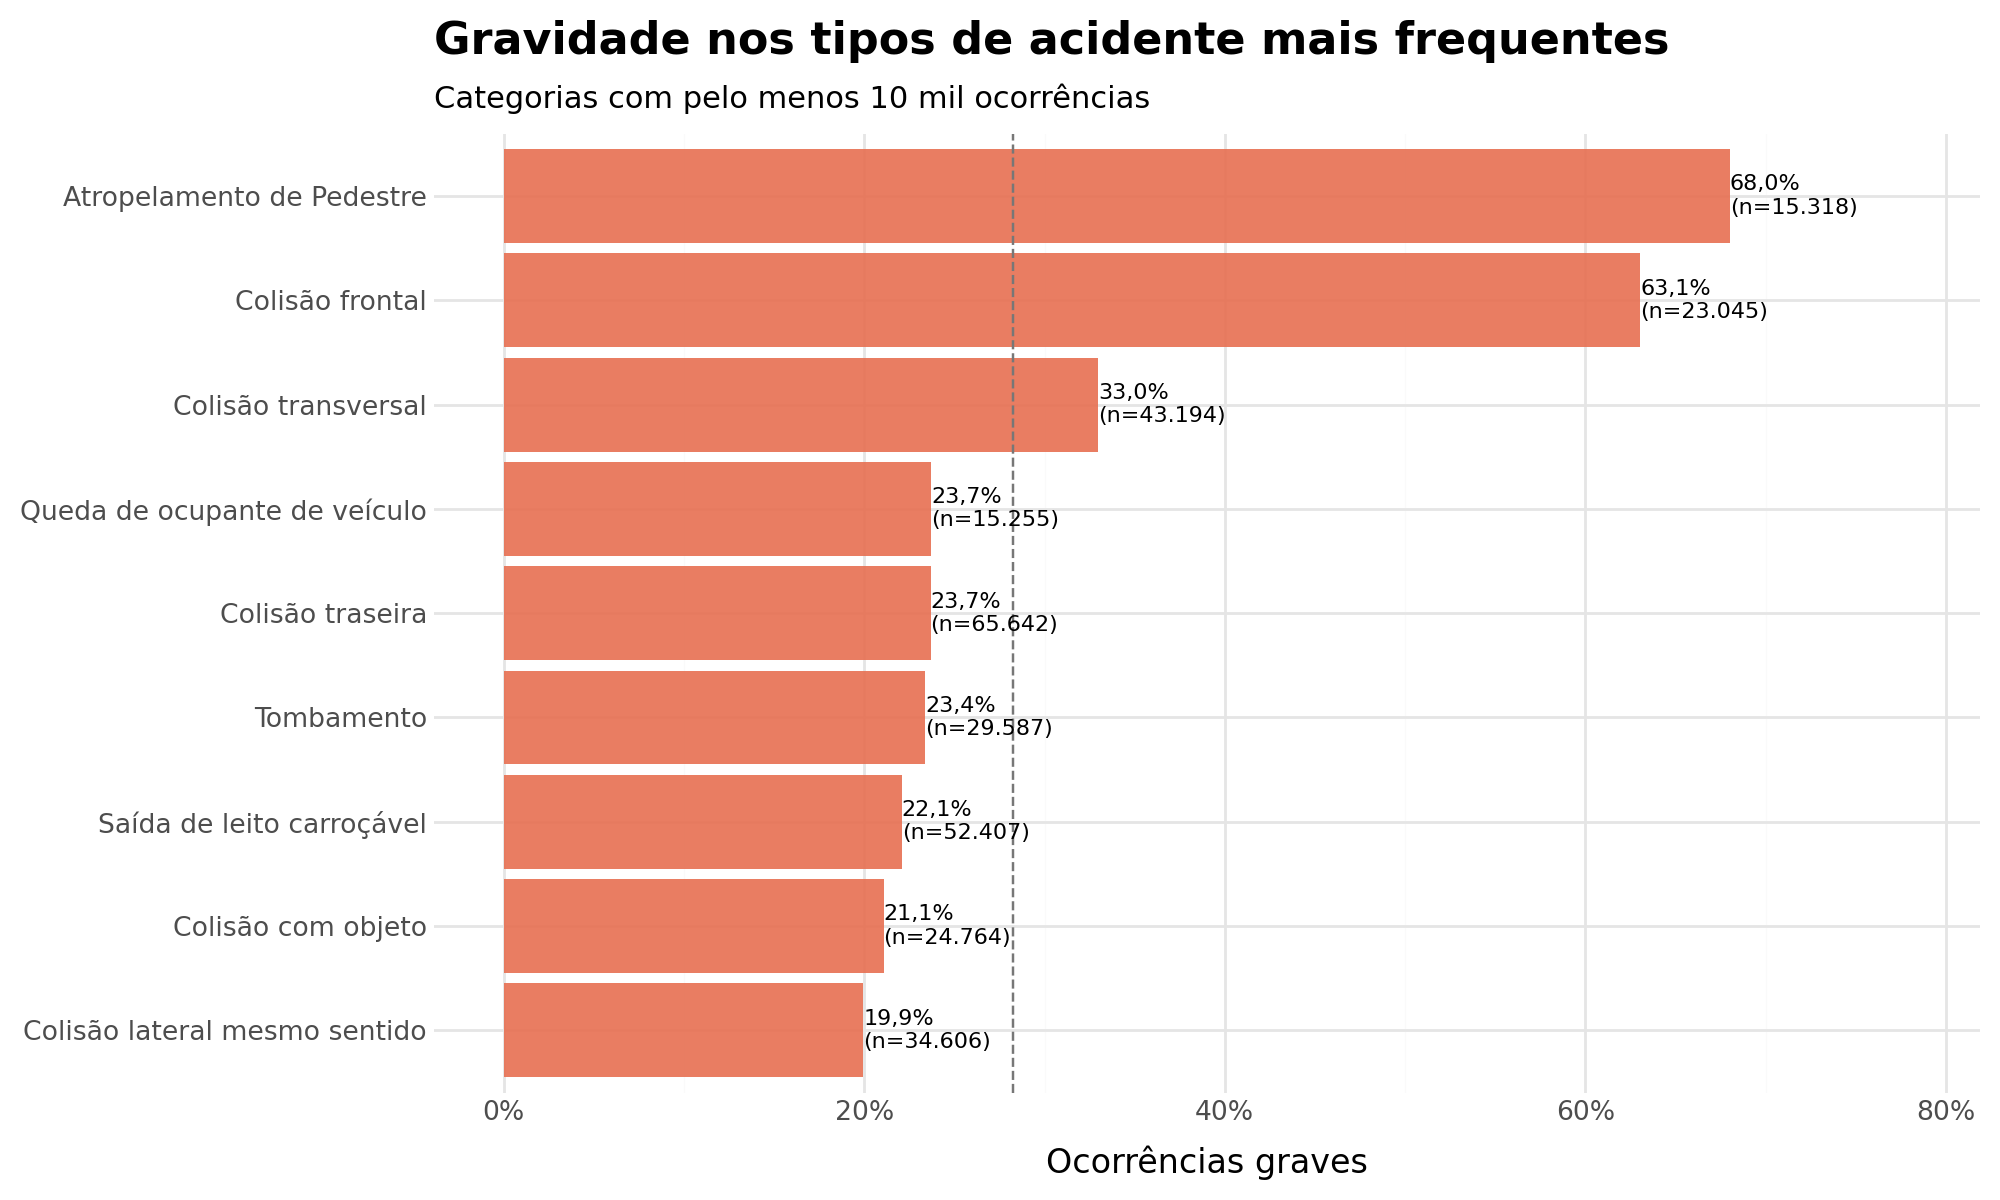

In [8]:
grafico_tipo = (
    ggplot(
        por_tipo,
        aes(x="reorder(tipo_acidente, prop_grave)", y="prop_grave")
    )
    + geom_col(fill="#E76F51", alpha=0.9)
    + geom_hline(yintercept=media_grave, linetype="dashed", color="#777777")
    + geom_text(aes(label="rótulo"), ha="left", size=8)
    + coord_flip()
    + scale_y_continuous(labels=percent_format(), limits=(0, 0.78))
    + labs(
        x="",
        y="Ocorrências graves",
        title="Gravidade nos tipos de acidente mais frequentes",
        subtitle="Categorias com pelo menos 10 mil ocorrências"
    )
)

grafico_tipo

Entre os tipos frequentes, atropelamento de pedestre (68,0%; n=15.318) e colisão frontal (63,1%; n=23.045) apresentam as maiores proporções graves. Como o tipo é definido depois do acidente, esse resultado descreve a dinâmica da ocorrência e entra apenas no Modelo B.

### 4.3 Como pista e trecho aparecem em conjunto?

In [9]:
pista_trecho = base.groupby(
    ["tipo_pista", "trecho"],
    as_index=False,
    observed=True
).agg(
    ocorrencias=("id", "size"),
    prop_grave=("grave", "mean")
)

pista_trecho["tipo_pista"] = pd.Categorical(
    pista_trecho["tipo_pista"],
    categories=["Simples", "Dupla", "Múltipla"],
    ordered=True
)
pista_trecho["n"] = pista_trecho["ocorrencias"].map("{:,.0f}".format).str.replace(",", ".")
pista_trecho["percentual"] = pista_trecho["prop_grave"].map("{:.1%}".format).str.replace(".", ",")
pista_trecho["rótulo"] = pista_trecho["percentual"] + "\n(n=" + pista_trecho["n"] + ")"
pista_trecho["posição"] = pista_trecho["prop_grave"] + 0.008

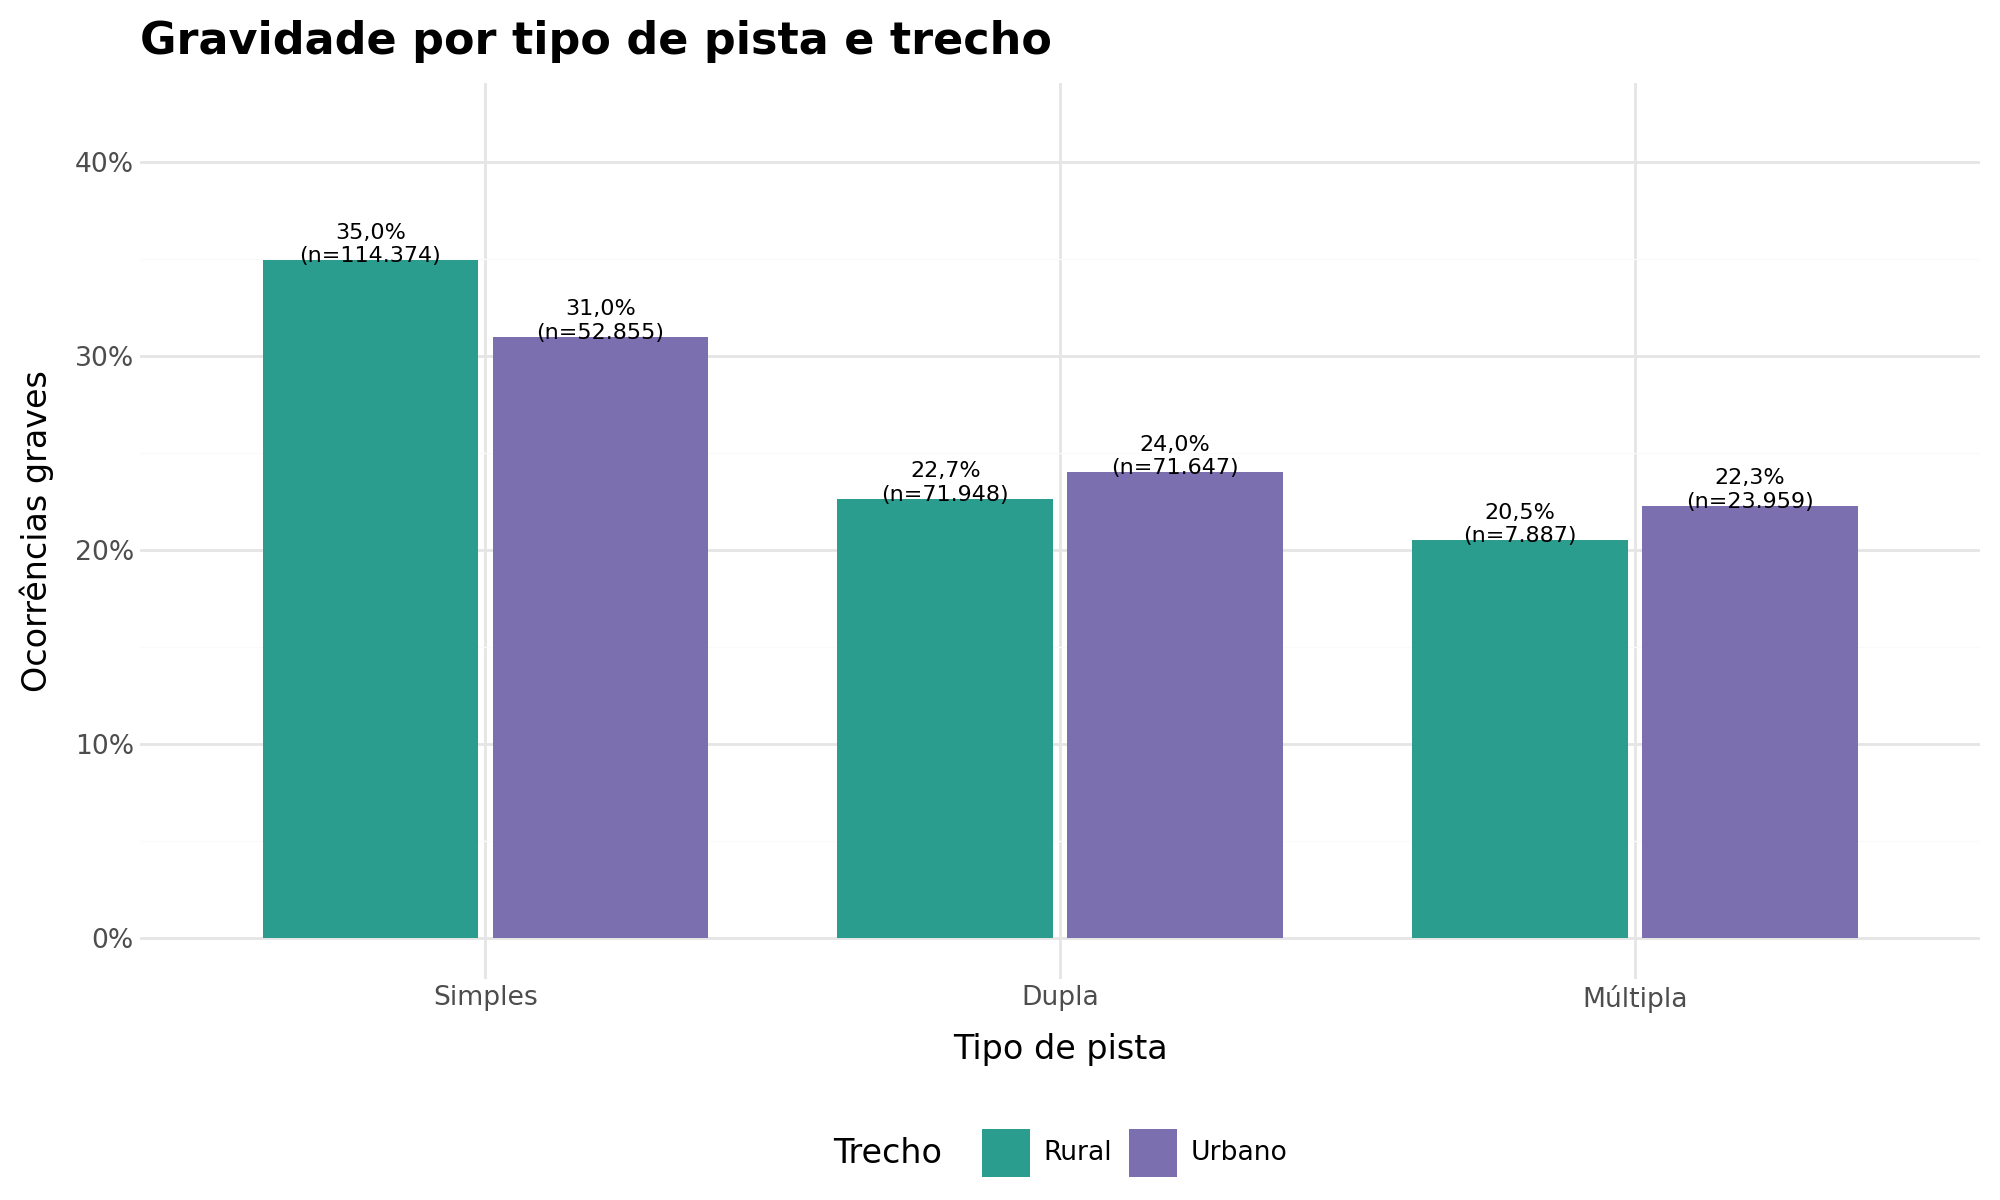

In [10]:
grafico_pista = (
    ggplot(pista_trecho, aes(x="tipo_pista", y="prop_grave", fill="trecho"))
    + geom_col(position=position_dodge(width=0.8), width=0.75)
    + geom_text(
        aes(y="posição", label="rótulo"),
        position=position_dodge(width=0.8),
        size=8
    )
    + scale_y_continuous(labels=percent_format(), limits=(0, 0.42))
    + scale_fill_manual(values={"Rural": "#2A9D8F", "Urbano": "#7B6FB0"})
    + labs(
        x="Tipo de pista",
        y="Ocorrências graves",
        fill="Trecho",
        title="Gravidade por tipo de pista e trecho"
    )
    + theme(legend_position="bottom")
)

grafico_pista

Pistas simples apresentam as maiores proporções: 35,0% no trecho rural e 31,0% no urbano. Em pistas duplas e múltiplas, os valores ficam entre 20,5% e 24,0%. A composição ajuda a explicar o total: pista simples representa 58,9% das ocorrências rurais e 35,6% das urbanas. Por isso, pista e trecho também são examinados por uma interação no modelo.

## 5. Modelos de associação

As regressões logísticas usam manhã, SP, céu claro, pista dupla e trecho urbano como referências. O Modelo A controla horário, UF, clima, pista e trecho. Primeiro é estimada uma versão aditiva; depois, a interação pista × trecho. O Modelo B mantém essa interação e acrescenta tipo, causa e veículos. Variáveis que revelam o desfecho, como mortos e feridos graves, não são usadas como preditoras.

In [11]:
import statsmodels.formula.api as smf
from scipy.stats import chi2

formula_contexto = """
grave ~ C(faixa_horaria, Treatment(reference='Manhã'))
      + C(uf, Treatment(reference='SP'))
      + C(condicao_metereologica, Treatment(reference='Céu Claro'))
      + C(tipo_pista, Treatment(reference='Dupla'))
      + C(trecho, Treatment(reference='Urbano'))
"""

formula_interacao = """
grave ~ C(faixa_horaria, Treatment(reference='Manhã'))
      + C(uf, Treatment(reference='SP'))
      + C(condicao_metereologica, Treatment(reference='Céu Claro'))
      + C(tipo_pista, Treatment(reference='Dupla'))
        * C(trecho, Treatment(reference='Urbano'))
"""

modelo_contexto = smf.logit(formula_contexto, data=treino).fit(disp=False)
modelo_interacao = smf.logit(formula_interacao, data=treino).fit(disp=False)

estatistica_lr = 2 * (modelo_interacao.llf - modelo_contexto.llf)
graus_liberdade = int(modelo_interacao.df_model - modelo_contexto.df_model)
valor_p_lr = chi2.sf(estatistica_lr, graus_liberdade)

assert modelo_contexto.mle_retvals["converged"]
assert modelo_interacao.mle_retvals["converged"]
assert valor_p_lr < 0.001

A interação reduz o AIC de 312.333,16 para 312.209,03. O teste de razão de verossimilhanças resulta em 128,1, com 2 graus de liberdade e `p < 0,001`. A versão com interação é, portanto, adotada como Modelo A final.

In [12]:
contagens_causas = treino["causa_acidente"].value_counts()
causas_comuns = set(contagens_causas[contagens_causas >= 500].index)

treino["causa_modelo"] = treino["causa_acidente"].where(
    treino["causa_acidente"].isin(causas_comuns),
    "Outras"
)
teste["causa_modelo"] = teste["causa_acidente"].where(
    teste["causa_acidente"].isin(causas_comuns),
    "Outras"
)

formula_ampliado = """
grave ~ C(faixa_horaria, Treatment(reference='Manhã'))
      + C(uf, Treatment(reference='SP'))
      + C(condicao_metereologica, Treatment(reference='Céu Claro'))
      + C(tipo_pista, Treatment(reference='Dupla'))
        * C(trecho, Treatment(reference='Urbano'))
      + C(tipo_acidente, Treatment(reference='Colisão traseira'))
      + C(causa_modelo, Treatment(reference='Reação tardia ou ineficiente do condutor'))
      + veiculos
"""

modelo_ampliado = smf.logit(
    formula_ampliado,
    data=treino
).fit(disp=False, maxiter=100)

teste["prob_contexto_interacao"] = modelo_interacao.predict(teste)
teste["prob_ampliado"] = modelo_ampliado.predict(teste)

assert modelo_ampliado.mle_retvals["converged"]
assert teste["prob_contexto_interacao"].between(0, 1).all()
assert teste["prob_ampliado"].between(0, 1).all()

### 5.1 Resultados selecionados

Razões de chances (OR) acima de 1 indicam chances relativas maiores que a referência; valores abaixo de 1 indicam chances menores. A tabela mostra somente termos definidos por relevância analítica. UF permanece como controle, mas seus coeficientes não são impressos.

In [13]:
def tabela_or(modelo, termos, nome_modelo):
    intervalos = modelo.conf_int()
    linhas = []

    for termo, rótulo in termos.items():
        linhas.append({
            "modelo": nome_modelo,
            "termo": rótulo,
            "OR": np.exp(modelo.params.loc[termo]),
            "IC 95% inferior": np.exp(intervalos.loc[termo, 0]),
            "IC 95% superior": np.exp(intervalos.loc[termo, 1])
        })

    return pd.DataFrame(linhas)


termos_contexto = {
    "C(faixa_horaria, Treatment(reference='Manhã'))[T.Madrugada]": "Madrugada",
    "C(faixa_horaria, Treatment(reference='Manhã'))[T.Noite]": "Noite",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Chuva]": "Chuva",
    "C(condicao_metereologica, Treatment(reference='Céu Claro'))[T.Nevoeiro/Neblina]": "Nevoeiro/Neblina",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Simples]": "Pista simples",
    "C(trecho, Treatment(reference='Urbano'))[T.Rural]": "Trecho rural",
    "C(tipo_pista, Treatment(reference='Dupla'))[T.Simples]:C(trecho, Treatment(reference='Urbano'))[T.Rural]": "Pista simples × trecho rural"
}

termos_ampliado = {
    "C(tipo_acidente, Treatment(reference='Colisão traseira'))[T.Atropelamento de Pedestre]": "Atropelamento de pedestre",
    "C(tipo_acidente, Treatment(reference='Colisão traseira'))[T.Colisão frontal]": "Colisão frontal",
    "C(tipo_acidente, Treatment(reference='Colisão traseira'))[T.Engavetamento]": "Engavetamento",
    "C(tipo_acidente, Treatment(reference='Colisão traseira'))[T.Incêndio]": "Incêndio",
    "C(causa_modelo, Treatment(reference='Reação tardia ou ineficiente do condutor'))[T.Ausência de reação do condutor]": "Ausência de reação do condutor",
    "C(causa_modelo, Treatment(reference='Reação tardia ou ineficiente do condutor'))[T.Velocidade Incompatível]": "Velocidade incompatível",
    "C(causa_modelo, Treatment(reference='Reação tardia ou ineficiente do condutor'))[T.Condutor deixou de manter distância do veículo da frente]": "Distância insuficiente",
    "C(causa_modelo, Treatment(reference='Reação tardia ou ineficiente do condutor'))[T.Ingestão de álcool pelo condutor]": "Ingestão de álcool",
    "veiculos": "Número de veículos"
}

resultados_or = pd.concat([
    tabela_or(modelo_interacao, termos_contexto, "A — Contexto"),
    tabela_or(modelo_ampliado, termos_ampliado, "B — Ampliado")
], ignore_index=True)

resultados_or.round(2)

,modelo,termo,OR,IC 95% inferior,IC 95% superior
0,A — Contexto,Madrugada,1.34,1.30,1.38
1,A — Contexto,Noite,1.47,1.43,1.50
2,A — Contexto,Chuva,0.80,0.77,0.82
3,A — Contexto,Nevoeiro/Neblina,1.09,0.99,1.19
4,A — Contexto,Pista simples,1.38,1.34,1.42
5,A — Contexto,Trecho rural,0.96,0.93,0.99
6,A — Contexto,Pista simples × trecho rural,1.24,1.19,1.29
7,B — Ampliado,Atropelamento de pedestre,5.12,4.79,5.46
8,B — Ampliado,Colisão frontal,3.73,3.57,3.90
9,B — Ampliado,Engavetamento,0.40,0.36,0.43


No Modelo A, ocorrências noturnas apresentam OR 1,47 em relação à manhã, e a madrugada, OR 1,34. O OR 0,96 de trecho rural compara rural e urbano somente entre pistas duplas, a referência. Em trecho urbano, pista simples apresenta OR 1,38 contra pista dupla. No trecho rural, o multiplicador adicional da interação é 1,24, resultando em OR combinado próximo de 1,71.

No Modelo B, atropelamento de pedestre apresenta OR próximo de 5,12 e colisão frontal, 3,73, ambos contra colisão traseira. Cada veículo adicional está associado a OR 1,18. O OR 0,62 para ingestão de álcool não indica proteção: a comparação inclui somente acidentes registrados e controla informações posteriores, como o tipo do acidente. Esses valores não são aumentos de probabilidade nem demonstram causalidade.

## 6. Avaliação em 2025

O teste contém 72.529 ocorrências, das quais 28,25% são graves. A comparação usa o Modelo A final e o Modelo B. AUC-ROC e PR-AUC avaliam as probabilidades; precisão e revocação usam o limiar fixo de 0,5.

In [14]:
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score
)

modelos_avaliados = {
    "A — Contexto": teste["prob_contexto_interacao"],
    "B — Ampliado": teste["prob_ampliado"]
}

linhas_metricas = []

for nome, probabilidades in modelos_avaliados.items():
    previsoes = (probabilidades >= 0.5).astype(int)
    vn, fp, fn, vp = confusion_matrix(teste["grave"], previsoes).ravel()

    linhas_metricas.append({
        "modelo": nome,
        "AUC-ROC": roc_auc_score(teste["grave"], probabilidades),
        "PR-AUC": average_precision_score(teste["grave"], probabilidades),
        "precisão": precision_score(teste["grave"], previsoes),
        "revocação": recall_score(teste["grave"], previsoes),
        "VP": vp,
        "FP": fp,
        "VN": vn,
        "FN": fn
    })

tabela_metricas = pd.DataFrame(linhas_metricas)
tabela_metricas.round(3)

,modelo,AUC-ROC,PR-AUC,precisão,revocação,VP,FP,VN,FN
0,A — Contexto,0.610,0.377,0.530,0.023,465,413,51623,20028
1,B — Ampliado,0.704,0.515,0.653,0.253,5175,2746,49290,15318


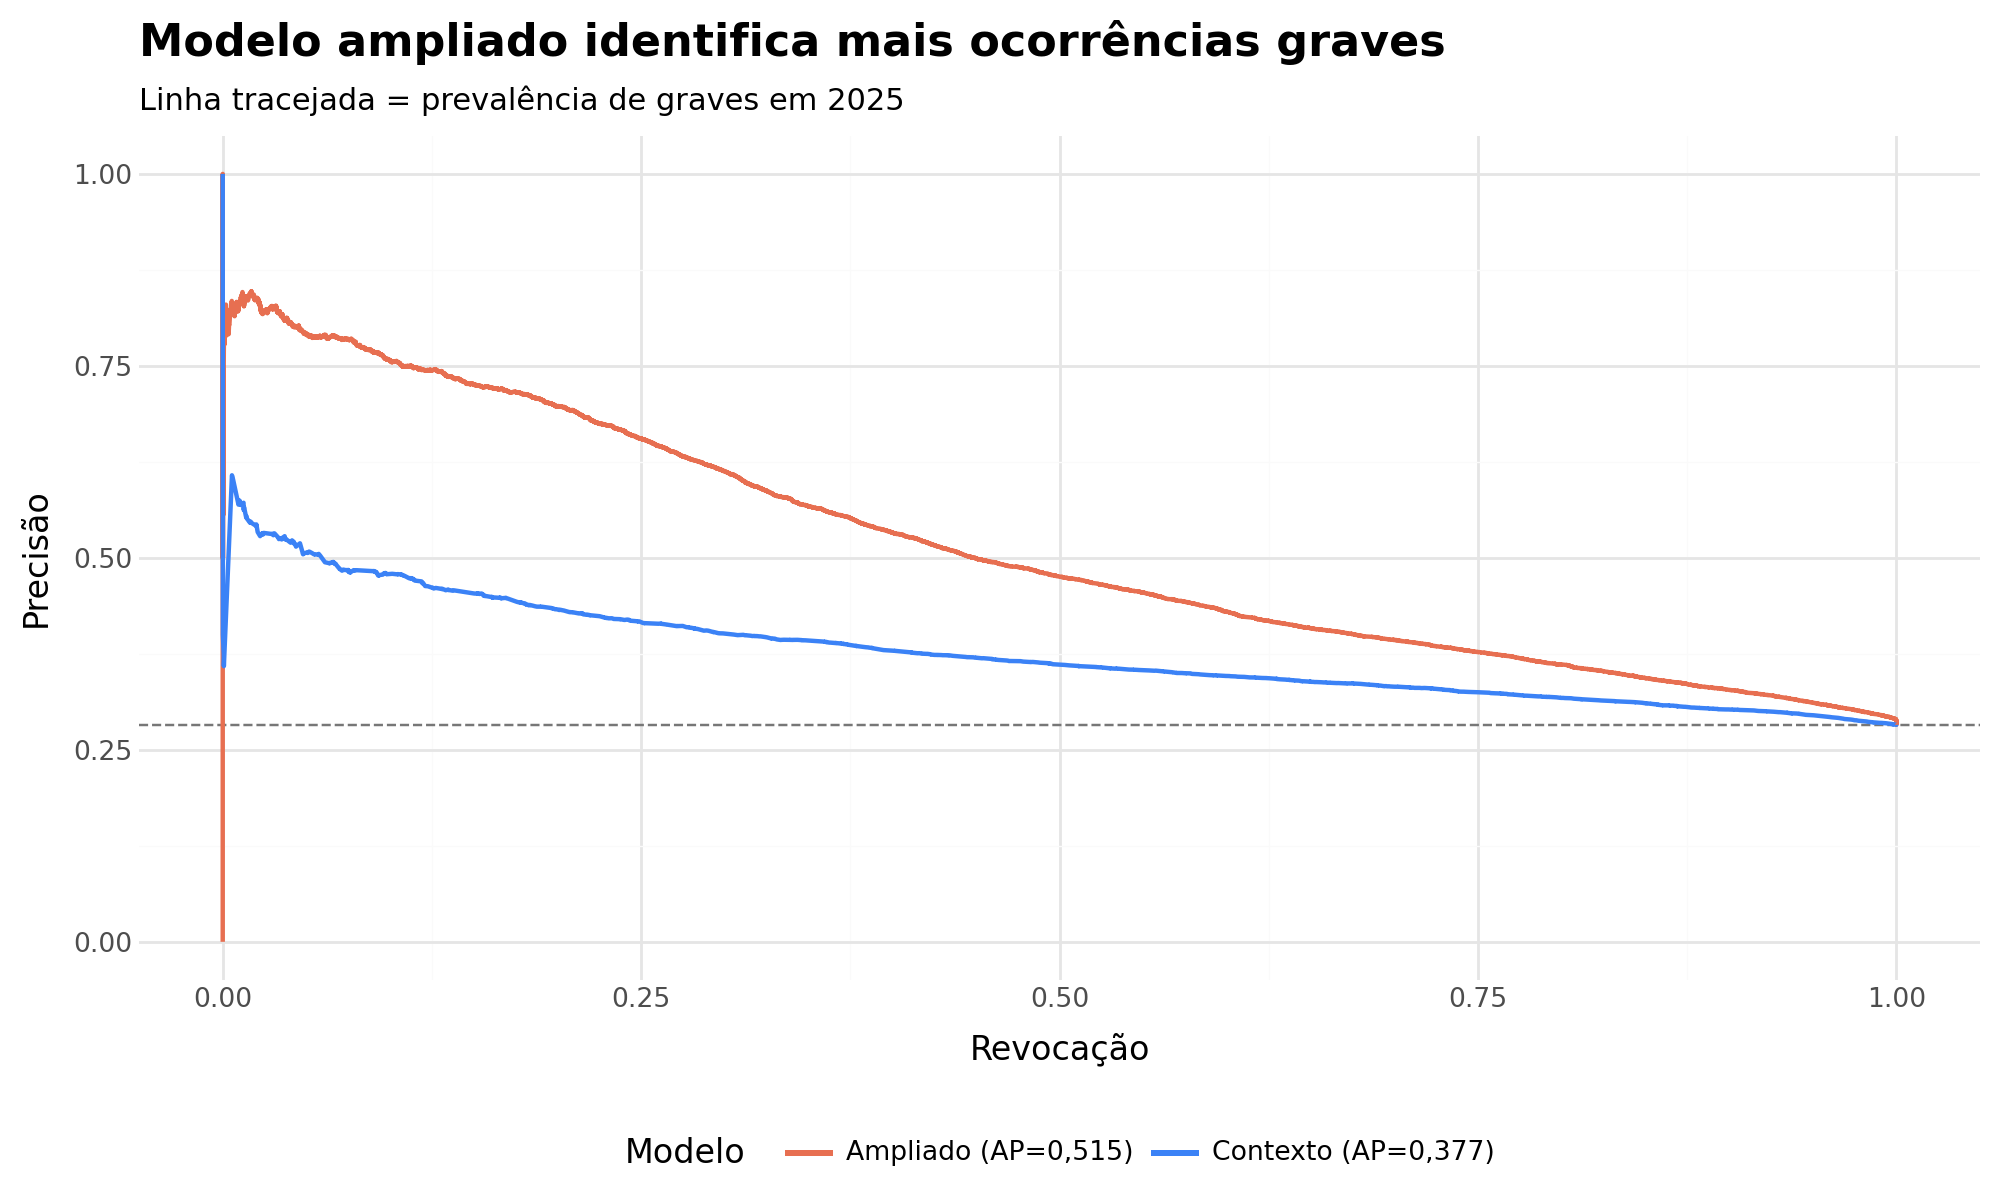

In [15]:
ap_contexto = tabela_metricas.loc[0, "PR-AUC"]
ap_ampliado = tabela_metricas.loc[1, "PR-AUC"]
nome_contexto = f"Contexto (AP={ap_contexto:.3f})".replace(".", ",")
nome_ampliado = f"Ampliado (AP={ap_ampliado:.3f})".replace(".", ",")

linhas_curva = []

for nome, probabilidades in {
    nome_contexto: teste["prob_contexto_interacao"],
    nome_ampliado: teste["prob_ampliado"]
}.items():
    precisao, revocacao, _ = precision_recall_curve(teste["grave"], probabilidades)
    linhas_curva.append(pd.DataFrame({
        "revocação": revocacao,
        "precisão": precisao,
        "modelo": nome
    }))

curvas_pr = pd.concat(linhas_curva, ignore_index=True)
prevalencia_2025 = teste["grave"].mean()

grafico_pr = (
    ggplot(curvas_pr, aes(x="revocação", y="precisão", color="modelo"))
    + geom_hline(yintercept=prevalencia_2025, linetype="dashed", color="#777777")
    + geom_line(size=0.9)
    + scale_color_manual(values={
        nome_contexto: "#3B82F6",
        nome_ampliado: "#E76F51"
    })
    + coord_cartesian(xlim=(0, 1), ylim=(0, 1))
    + labs(
        x="Revocação",
        y="Precisão",
        color="Modelo",
        title="Modelo ampliado identifica mais ocorrências graves",
        subtitle="Linha tracejada = prevalência de graves em 2025"
    )
    + theme(legend_position="bottom")
)

grafico_pr

O Modelo A alcança AUC-ROC 0,610 e PR-AUC 0,377. O Modelo B melhora para 0,704 e 0,515, respectivamente. No limiar de 0,5, o Modelo B tem precisão de 65,3% e revocação de 25,3%: cerca de dois terços dos casos sinalizados são graves, mas apenas um quarto de todos os graves é identificado. O ganho vem, em parte, de informações conhecidas somente depois da ocorrência.

## 7. Conclusão

Entre 2021 e 2025, a quantidade de acidentes registrados aumentou, mas a proporção grave permaneceu próxima de 28,3%. Portanto, a principal mudança do período está nas contagens, não na participação relativa das ocorrências graves.

Atropelamentos de pedestres e colisões frontais apresentam as maiores proporções graves entre os tipos frequentes. Pistas simples também apresentam proporções maiores, principalmente em trechos rurais. A regressão confirma que a associação entre pista e gravidade varia conforme o trecho.

O modelo ampliado separa melhor acidentes graves e não graves que o modelo formado apenas por contexto, mas ainda identifica somente 25,3% dos graves no limiar de 0,5. Além disso, seu ganho depende de tipo e causa, informações registradas após o acidente; por isso, ele não deve ser interpretado como ferramenta de previsão anterior à ocorrência.

Os resultados respondem à pergunta ao identificar características associadas à gravidade nos registros da PRF, sem demonstrar causalidade. A ausência de medidas de exposição impede comparar risco de trafegar entre locais, e as divergências no campo `pessoas` reforçam a necessidade de cautela na interpretação.

## Referências

IPEA; POLÍCIA RODOVIÁRIA FEDERAL. **Acidentes de trânsito nas rodovias federais brasileiras: caracterização, tendências e custos para a sociedade**. Brasília: Ipea, 2015.

POLÍCIA RODOVIÁRIA FEDERAL. **Dados Abertos da PRF**. Disponível em: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf>. Acesso em: 19 out. 2026.

POLÍCIA RODOVIÁRIA FEDERAL. **Dicionário de dados — Acidentes**. Disponível em: <https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dicionario-acidentes>. Acesso em: 19 out. 2026.